# Kvasir-SEG: segmentation starter

**Goal:** implement a compact U-Net and test how training-set size affects Dice/IoU. No results are prefilled.

Dataset terms and citation: https://datasets.simula.no/kvasir-seg/  
In Colab, select a GPU runtime. Upload/extract the dataset, then set `DATA_DIR` below.

In [ ]:
!pip -q install scikit-learn matplotlib pillow tqdm

In [ ]:
import torch
import numpy as np
import pandas as pd
from torch import nn
from PIL import Image
from pathlib import Path
from google.colab import drive
import sys, random, json, time
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

# Mount Google Drive to access files
drive.mount('/content/drive')

SEED = 42
IMAGE_SIZE = 256
BATCH_SIZE = 64
EPOCHS = 150

# File Path in Google Drive
DATA_DIR = Path("/content/drive/MyDrive/Colab Notebooks/medical_imaging_portfolio/01_kvasir_segmentation/notebooks/kvasir-seg")
OUT_DIR = Path("/content/drive/MyDrive/Colab Notebooks/medical_imaging_portfolio/01_kvasir_segmentation/notebooks/outputs/segmentation")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Set a pseudo-random number seed generator
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cpu


In [ ]:
# Dataset helpers
def discover_pairs(data_dir):
    image_dir, mask_dir = data_dir / "images", data_dir / "masks"
    if not image_dir.exists() or not mask_dir.exists():
        raise FileNotFoundError(
            f"Expected {image_dir} and {mask_dir}. Check the extracted folder layout."
        )
    masks = {p.stem: p for p in mask_dir.iterdir() if p.is_file()}
    pairs = sorted((p, masks[p.stem]) for p in image_dir.iterdir()
                   if p.is_file() and p.stem in masks)
    if not pairs: raise RuntimeError("No matching image/mask pairs found.")
    return pairs

class PolypDataset(torch.utils.data.Dataset):
    def __init__(self, pairs, image_size=IMAGE_SIZE):
        self.pairs, self.image_size = list(pairs), image_size
    def __len__(self): return len(self.pairs)
    def __getitem__(self, i):
        ip, mp = self.pairs[i]
        image = Image.open(ip).convert("RGB").resize((self.image_size, self.image_size), Image.Resampling.BILINEAR)
        mask = Image.open(mp).convert("L").resize((self.image_size, self.image_size), Image.Resampling.NEAREST)
        x = torch.from_numpy(np.asarray(image, dtype=np.float32).copy() / 255.).permute(2,0,1)
        y = torch.from_numpy((np.asarray(mask, dtype=np.uint8).copy() > 0).astype(np.float32)).unsqueeze(0)
        return x, y

pairs = discover_pairs(DATA_DIR)
indices = np.arange(len(pairs))
train_idx, temp_idx = train_test_split(indices, test_size=0.30, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, random_state=SEED)
print(f"Images: {len(pairs)} | train={len(train_idx)} val={len(val_idx)} test={len(test_idx)}")

Images: 1000 | train=700 val=150 test=150


## Implement the model

Implement a compact U-Net or import your own. It must return **one-channel logits** with shape `[batch, 1, height, width]`. Keep the same architecture for all data fractions.

In [ ]:
# Create Model
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        layers = [ nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False)]
        layers.append(nn.BatchNorm2d(out_ch))
        layers.append(nn.ReLU(inplace=True))
        layers.append(nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False))
        layers.append(nn.BatchNorm2d(out_ch))
        layers.append(nn.ReLU(inplace=True))
        self.block = nn.Sequential(*layers)

    def forward(self, x):
      return self.block(x)

class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=16):
        super().__init__()

        b = base
        self.pool = nn.MaxPool2d(2)

        # Encoder
        self.ec1 = DoubleConv(in_ch, b)
        self.ec2 = DoubleConv(b, b*2)
        self.ec3 = DoubleConv(b*2, b*4)
        self.ec4 = DoubleConv(b*4, b*8)

        # Bottleneck
        self.bt = DoubleConv(b*8, b*16)

        # Decoder
        self.up4 = nn.ConvTranspose2d(b*16, b*8, kernel_size=2, stride=2)
        self.dc4 = DoubleConv(b*16, b*8)
        self.up3 = nn.ConvTranspose2d(b*8, b*4, kernel_size=2, stride=2)
        self.dc3 = DoubleConv(b*8, b*4)
        self.up2 = nn.ConvTranspose2d(b*4, b*2, kernel_size=2, stride=2)
        self.dc2 = DoubleConv(b*4, b*2)
        self.up1 = nn.ConvTranspose2d(b*2, b, kernel_size=2, stride=2)
        self.dc1 = DoubleConv(b*2, b)

        self.head = nn.Conv2d(b, out_ch, kernel_size=1)

    def forward(self, x):
      e1 = self.ec1(x)
      e2 = self.ec2(self.pool(e1))
      e3 = self.ec3(self.pool(e2))
      e4 = self.ec4(self.pool(e3))
      m  = self.bt(self.pool(e4))

      d4 = self.dc4(torch.cat([self.up4(m), e4], dim=1))
      d3 = self.dc3(torch.cat([self.up3(d4), e3], dim=1))
      d2 = self.dc2(torch.cat([self.up2(d3), e2], dim=1))
      d1 = self.dc1(torch.cat([self.up1(d2), e1], dim=1))
      return self.head(d1)

      model = UNet().to(device)

Input shape:  torch.Size([1, 3, 256, 256])
Output shape: torch.Size([1, 1, 256, 256])


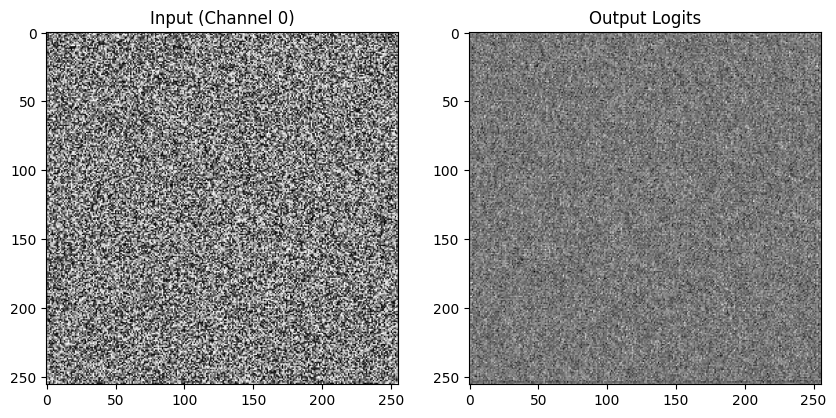

In [ ]:
# Instantiate the model
model = UNet().to(device)

# Define a valid 4D mock input tensor [batch_size, channels, height, width]
# Since UNet defaults to 3 input channels (RGB) and 256x256 pixels:
x = torch.rand(1, 3, 256, 256).to(device)

# Propagate through the network
x_rec = model(x)

print('Input shape: ', x.shape)
print('Output shape:', x_rec.shape)

# Display the input (first channel) and corresponding output mask
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(x[0, 0].cpu().numpy(), origin='upper', cmap='gray')
plt.title("Input (Channel 0)")

plt.subplot(1, 2, 2)
plt.imshow(x_rec[0, 0].detach().cpu().numpy(), origin='upper', cmap='gray')
plt.title("Output Logits")
plt.show()

In [ ]:
"""print('model structure:\n', model)

for name, param in model.named_parameters():
    print('layer: {} | size: {} \nweight values : {} \n'.format(name, param.size(), param.ravel()[:100]))

num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total trainable parameters: {num_params}')"""

In [ ]:
# Instantiate both original and larger U-Net models
model = UNet(base=16).to(device)
model_large = UNet(base=32).to(device)

def count_parameters(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

print(f"Original UNet (base=16) parameters: {count_parameters(model):,}")
print(f"Upgraded UNet (base=32) parameters: {count_parameters(model_large):,}")

Original UNet (base=16) parameters: 1,942,577
Upgraded UNet (base=32) parameters: 7,763,041


In [ ]:
# Helper functions for calculating validation metrics and running training loops

def dice_iou(logits, targets, eps=1e-7):
    """
    Calculate Dice and IoU coefficients for binary segmentation.
    """
    pred = torch.sigmoid(logits) >= 0.5
    target = targets >= 0.5
    dims = (1, 2, 3)
    inter = (pred & target).sum(dims).float()
    p, t = pred.sum(dims).float(), target.sum(dims).float()
    dice = (2 * inter + eps) / (p + t + eps)
    iou = (inter + eps) / (p + t - inter + eps)
    return dice.mean().item(), iou.mean().item()

def train_loop(dataloader, model, loss_fn, optimizer):
    """
    Standard PyTorch training loop with metric tracking.
    """
    size = len(dataloader.dataset)
    batch_size = dataloader.batch_size
    model.train()
    num_batches = len(dataloader)

    total_loss = 0.0
    total_dice = 0.0
    total_iou = 0.0

    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        # Compute prediction and loss
        logits = model(X)
        loss = loss_fn(logits, y)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Track metrics
        d, j = dice_iou(logits.detach(), y)
        total_loss += loss.item()
        total_dice += d
        total_iou += j

        if batch % 10 == 0:
            print(f"loss: {loss.item():>7f}  [{batch * batch_size + len(X):>5d}/{size:>5d}]")

    avg_loss = total_loss / num_batches
    avg_dice = total_dice / num_batches
    avg_iou = total_iou / num_batches
    return {"loss": avg_loss, "dice": avg_dice, "iou": avg_iou}

def test_loop(dataloader, model, loss_fn):
    """
    Standard evaluation/validation loop on a dataset.
    """
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)

    total_loss = 0.0
    total_dice = 0.0
    total_iou = 0.0

    with torch.no_grad():
        for batch, (X, y) in enumerate(dataloader):
            X, y = X.to(device), y.to(device)
            logits = model(X)

            loss = loss_fn(logits, y)
            d, j = dice_iou(logits, y)

            total_loss += loss.item()
            total_dice += d
            total_iou += j

    avg_loss = total_loss / num_batches
    avg_dice = total_dice / num_batches
    avg_iou = total_iou / num_batches
    print(f"test evaluation: \n avg loss: {avg_loss:.6f} | avg dice: {avg_dice:.6f} | avg iou: {avg_iou:.6f}\n")
    return {"loss": avg_loss, "dice": avg_dice, "iou": avg_iou}

## Train and compare labeled-data fractions

This cell assumes the model TODOs are implemented. Use the validation set for model selection. The test set should be evaluated only after you settle the configuration.

In [ ]:
# Initialize trackers for plotting
train_losses = []
val_losses = []

# Load datasets
val_loader = DataLoader(Subset(PolypDataset(pairs), val_idx), batch_size=BATCH_SIZE, shuffle=False)
train_loader = DataLoader(Subset(PolypDataset(pairs), train_idx), batch_size=BATCH_SIZE, shuffle=True)

seed_everything()
model = UNet(base=32).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
best_val_dice, best_state = -1, None

for epoch in range(EPOCHS):
    print(f"\n--- Epoch {epoch+1}/{EPOCHS} ---")

    # Run training loop
    train_metrics = train_loop(train_loader, model, criterion, optimizer)
    train_losses.append(train_metrics["loss"])

    # Run validation loop (eval mode, no grad/optimizer)
    val_metrics = test_loop(val_loader, model, criterion)
    val_losses.append(val_metrics["loss"])

    # Save the best model configuration
    if val_metrics["dice"] > best_val_dice:
        best_val_dice = val_metrics["dice"]
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    print(f"Epoch {epoch+1} summary: Train Loss={train_metrics['loss']:.4f} | Val Loss={val_metrics['loss']:.4f} | Val Dice={val_metrics['dice']:.4f}")

# Restore best weights and save
model.load_state_dict(best_state)
torch.save(best_state, OUT_DIR / "unet_base32_1.00.pt")
print("\nTraining complete! Best validation Dice score:", best_val_dice)


--- Epoch 1/150 ---
loss: 0.740814  [   64/  700]
loss: 0.524858  [  700/  700]
test evaluation: 
 avg loss: 0.592364 | avg dice: 0.006792 | avg iou: 0.003618

Epoch 1 summary: Train Loss=0.5993 | Val Loss=0.5924 | Val Dice=0.0068

--- Epoch 2/150 ---
loss: 0.525498  [   64/  700]
loss: 0.465654  [  700/  700]
test evaluation: 
 avg loss: 0.719464 | avg dice: 0.319126 | avg iou: 0.207342

Epoch 2 summary: Train Loss=0.4912 | Val Loss=0.7195 | Val Dice=0.3191

--- Epoch 3/150 ---
loss: 0.461748  [   64/  700]
loss: 0.424674  [  700/  700]
test evaluation: 
 avg loss: 0.695003 | avg dice: 0.316240 | avg iou: 0.204044

Epoch 3 summary: Train Loss=0.4499 | Val Loss=0.6950 | Val Dice=0.3162

--- Epoch 4/150 ---
loss: 0.424364  [   64/  700]
loss: 0.404207  [  700/  700]
test evaluation: 
 avg loss: 0.424158 | avg dice: 0.407779 | avg iou: 0.297371

Epoch 4 summary: Train Loss=0.4193 | Val Loss=0.4242 | Val Dice=0.4078

--- Epoch 5/150 ---
loss: 0.396803  [   64/  700]
loss: 0.375343  [  70

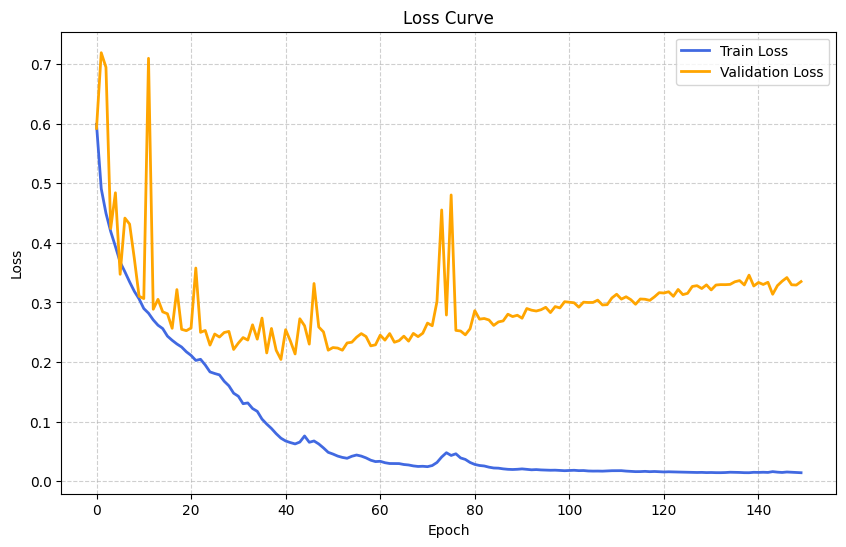

Loss curve saved to: /content/drive/MyDrive/Colab Notebooks/medical_imaging_portfolio/01_kvasir_segmentation/notebooks/outputs/segmentation/unet_loss_curves.png


In [ ]:
# Plot loss curves using tracked metrics from the training run
plt.figure(figsize=(10, 6))
plt.plot(train_losses, label='Train Loss', color='royalblue', linewidth=2)
plt.plot(val_losses, label='Validation Loss', color='orange', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss Curve')
plt.grid(True, linestyle='--', alpha=0.6)

# Save the loss curve visualization
plot_path = OUT_DIR / "unet_loss_curves.png"
plt.savefig(plot_path, dpi=300)
plt.show()

print(f"Loss curve saved to: {plot_path}")

### Analysis of Baseline Training Dynamics (Loss Curve)

Severe Overfitting Beyond Epoch ~40–50:
-  Training loss converges smoothly toward near zero ($\sim 0.015$ by epoch 150).   
-  Validation loss hits a minimum around epoch 40–50 ($\sim 0.21$) before steadily drifting upward to $\sim 0.34$ by epoch 150. This divergence is a textbook signature of variance/overfitting: the network begins memorizing training sample specifics rather than generalizable lesion semantics.   

High Validation Variance & Spikes:
-  Marked spikes in validation loss (e.g., epochs ~10, ~46, and ~73–75) indicate optimization instability, often caused by a rigid or overly large learning rate on difficult validation batches.   
-  The lack of a dynamic learning rate decay prevents the network from stabilizing around flatter, more generalizable local minima.   

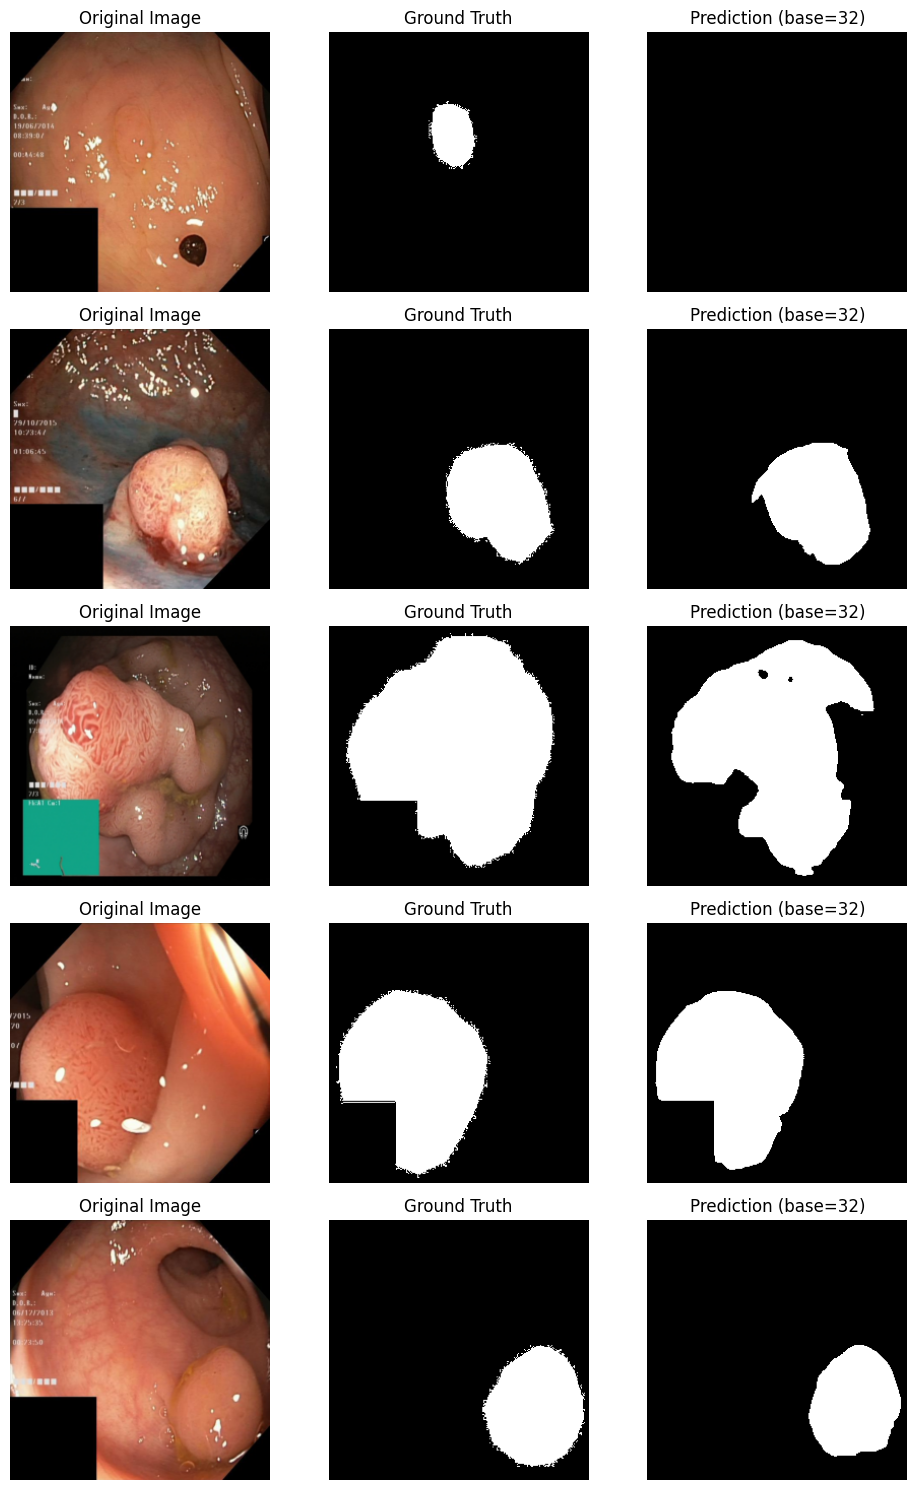

Visual comparison grid saved to: /content/drive/MyDrive/Colab Notebooks/medical_imaging_portfolio/01_kvasir_segmentation/notebooks/outputs/segmentation/predictions_comparison_grid.png


In [ ]:
# Load upgraded best-performing checkpoint (base=32)
best_checkpoint_path = OUT_DIR / "unet_base32_1.00.pt"
model_best = UNet(base=32).to(device)
model_best.load_state_dict(torch.load(best_checkpoint_path, map_location=device))
model_best.eval()

# Define the test dataset and extract a sample batch
test_dataset = Subset(PolypDataset(pairs), test_idx)
sample_loader = DataLoader(test_dataset, batch_size=5, shuffle=True)
sample_imgs, sample_masks = next(iter(sample_loader))

# Generate predictions
with torch.no_grad():
    logits = model_best(sample_imgs.to(device))
    preds = (torch.sigmoid(logits) >= 0.5).cpu().numpy()

sample_imgs = sample_imgs.cpu().numpy()
sample_masks = sample_masks.cpu().numpy()

# Plot the comparison grid
num_samples = len(sample_imgs)
fig, axes = plt.subplots(num_samples, 3, figsize=(10, num_samples * 3))

for i in range(num_samples):
    img = np.transpose(sample_imgs[i], (1, 2, 0))
    axes[i, 0].imshow(img)
    axes[i, 0].set_title("Original Image")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(sample_masks[i, 0], cmap='gray')
    axes[i, 1].set_title("Ground Truth")
    axes[i, 1].axis('off')

    axes[i, 2].imshow(preds[i, 0], cmap='gray')
    axes[i, 2].set_title("Prediction (base=32)")
    axes[i, 2].axis('off')

plt.tight_layout()
prediction_grid_path = OUT_DIR / "predictions_comparison_grid.png"
plt.savefig(prediction_grid_path, dpi=300)
plt.show()

print(f"Visual comparison grid saved to: {prediction_grid_path}")

### Analysis of Baseline Segmentation Qualitative Results (base=32)

-  Small Lesion False Negatives (Row 1): The model outputs an entirely blank prediction for the smaller polyp in Row 1. Standard pixel-wise BCE loss struggles with severe foreground-background class imbalance; because background pixels dominate, the model receives negligible penalty for simply predicting background across small structures.   

-  Boundary Jaggedness & Artifact Sensitivity (Rows 2–4): Predicted masks exhibit coarse, jagged perimeters and false holes/inclusions (e.g., Row 3 top region) caused by specular highlights (light reflections) and endoscopic artifacts (corner overlays/watermarks).   

-  Successful Cases (Rows 4 & 5): For medium-to-large, centrally positioned polyps with clear contrast, the base U-Net captures gross geometry reasonably well, showing that the core encoder-decoder bottleneck architecture is functional.

In [ ]:
# Configure training parameters and split sizes
config_data = {
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "epochs": EPOCHS,
    "optimizer": "Adam",
    "learning_rate": 1e-3,
    "batch_size": BATCH_SIZE,
    "train_size": len(train_idx),
    "val_size": len(val_idx),
    "test_size": len(test_idx)
}

config_path = OUT_DIR / "config.json"
with open(config_path, "w") as f:
    json.dump(config_data, f, indent=4)

print(f"Configuration JSON saved successfully to: {config_path}")
with open(config_path, "r") as f:
    print(f.read())

Configuration JSON saved successfully to: /content/drive/MyDrive/Colab Notebooks/medical_imaging_portfolio/01_kvasir_segmentation/notebooks/outputs/segmentation/config.json
{
    "seed": 42,
    "image_size": 256,
    "epochs": 150,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "batch_size": 64,
    "train_size": 700,
    "val_size": 150,
    "test_size": 150
}


### Optimization & Improvements

The baseline U-Net (base=32) exhibits pronounced overfitting after approximately epoch 45, with training loss continuing downward toward $\sim 0.01$ while validation loss climbs back up to $\sim 0.34$ with intermittent high-variance spikes.   
Qualitatively, standard BCE loss results in severe under-segmentation on small lesions (manifesting as complete false negatives) and shows vulnerability to illumination artifacts and endoscope watermarks.   

To address these specific failure modes, our revised pipeline introduces three complementary mechanisms:
1. Joint Image-Mask Augmentation (rotations, functional affine warps, and color jitter) to mitigate overfitting and enforce geometric invariance;
2. Compound BCE-Dice Loss to counteract extreme background-to-lesion class imbalance and recover fine/small structures;
3. Cosine Annealing LR Scheduling to eliminate validation volatility and promote convergence to stable, generalizable minima.

In [ ]:
import torchvision.transforms.functional as TF

class AugmentedPolypDataset(torch.utils.data.Dataset):
    def __init__(self, pairs, image_size=IMAGE_SIZE, augment=False):
        self.pairs = list(pairs)
        self.image_size = image_size
        self.augment = augment

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, i):
        ip, mp = self.pairs[i]
        image = Image.open(ip).convert("RGB").resize((self.image_size, self.image_size), Image.Resampling.BILINEAR)
        mask = Image.open(mp).convert("L").resize((self.image_size, self.image_size), Image.Resampling.NEAREST)

        if self.augment:
            # Random horizontal flipping
            if random.random() > 0.5:
                image = TF.hflip(image)
                mask = TF.hflip(mask)

            # Random vertical flipping
            if random.random() > 0.5:
                image = TF.vflip(image)
                mask = TF.vflip(mask)

            # Random rotation
            angle = random.randint(-30, 30)
            image = TF.rotate(image, angle)
            mask = TF.rotate(mask, angle)

            # Color jittering (only apply to image, not mask)
            if random.random() > 0.5:
                image = TF.adjust_brightness(image, random.uniform(0.8, 1.2))
                image = TF.adjust_contrast(image, random.uniform(0.8, 1.2))

        x = torch.from_numpy(np.asarray(image, dtype=np.float32).copy() / 255.).permute(2,0,1)
        y = torch.from_numpy((np.asarray(mask, dtype=np.uint8).copy() > 0).astype(np.float32)).unsqueeze(0)
        return x, y

class BCEWithDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5, eps=1e-7):
        super().__init__()
        self.bce_weight = bce_weight
        self.bce = nn.BCEWithLogitsLoss()
        self.eps = eps

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)

        # Dice loss
        probs = torch.sigmoid(logits)
        inter = (probs * targets).sum(dim=(1, 2, 3))
        union = probs.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))
        dice_loss = 1.0 - (2.0 * inter + self.eps) / (union + self.eps)

        return self.bce_weight * bce_loss + (1 - self.bce_weight) * dice_loss.mean()

In [ ]:
# Re-train the model with optimization enhancements
seed_everything()

# Datasets: Subset the raw pairs list directly to keep file paths intact
train_pairs = [pairs[idx] for idx in train_idx]
val_pairs = [pairs[idx] for idx in val_idx]

train_dataset_aug = AugmentedPolypDataset(train_pairs, augment=True)
val_dataset_clean = AugmentedPolypDataset(val_pairs, augment=False)

train_loader_aug = DataLoader(train_dataset_aug, batch_size=BATCH_SIZE, shuffle=True)
val_loader_clean = DataLoader(val_dataset_clean, batch_size=BATCH_SIZE, shuffle=False)

model_opt = UNet(base=32).to(device)
criterion_opt = BCEWithDiceLoss(bce_weight=0.5)
optimizer_opt = torch.optim.AdamW(model_opt.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_opt, T_max=EPOCHS)

train_losses_opt = []
val_losses_opt = []
best_val_dice_opt = -1
best_state_opt = None

for epoch in range(EPOCHS):
    # Train Step
    model_opt.train()
    num_batches = len(train_loader_aug)
    total_loss = 0.0
    for X, y in train_loader_aug:
        X, y = X.to(device), y.to(device)
        logits = model_opt(X)
        loss = criterion_opt(logits, y)

        optimizer_opt.zero_grad()
        loss.backward()
        optimizer_opt.step()
        total_loss += loss.item()

    avg_train_loss = total_loss / num_batches
    train_losses_opt.append(avg_train_loss)

    # Validation Step
    model_opt.eval()
    val_loss = 0.0
    total_dice = 0.0
    with torch.no_grad():
        for X, y in val_loader_clean:
            X, y = X.to(device), y.to(device)
            logits = model_opt(X)
            loss = criterion_opt(logits, y)
            val_loss += loss.item()
            d, _ = dice_iou(logits, y)
            total_dice += d

    avg_val_loss = val_loss / len(val_loader_clean)
    avg_val_dice = total_dice / len(val_loader_clean)
    val_losses_opt.append(avg_val_loss)

    scheduler.step()

    if avg_val_dice > best_val_dice_opt:
        best_val_dice_opt = avg_val_dice
        best_state_opt = {k: v.detach().cpu().clone() for k, v in model_opt.state_dict().items()}

    if (epoch + 1) % 5 == 0 or epoch == EPOCHS - 1:
        print(f"Epoch {epoch+1:02d}/{EPOCHS} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Dice: {avg_val_dice:.4f}")

# Save the best weights
model_opt.load_state_dict(best_state_opt)
torch.save(best_state_opt, OUT_DIR / "unet_base32_optimized.pt")
print(f"\nOptimized training complete! Best validation Dice score: {best_val_dice_opt:.4f}")

In [ ]:
# Plot comparison of loss curves
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Base Train Loss', color='gray', linestyle='--')
plt.plot(val_losses, label='Base Val Loss', color='orange', linestyle='--')
plt.plot(train_losses_opt, label='Opt Train Loss', color='royalblue')
plt.plot(val_losses_opt, label='Opt Val Loss', color='darkorange')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss Curve Comparison')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)
# Visualizing Sample Performance Improvements
test_dataset = Subset(PolypDataset(pairs), test_idx)
# Set shuffle=True to randomize the image choice
sample_loader = DataLoader(test_dataset, batch_size=1, shuffle=True)
img, mask = next(iter(sample_loader))

with torch.no_grad():
    model_best.eval()
    model_opt.eval()
    pred_base = (torch.sigmoid(model_best(img.to(device))) >= 0.5).cpu().numpy()[0, 0]
    pred_opt = (torch.sigmoid(model_opt(img.to(device))) >= 0.5).cpu().numpy()[0, 0]

plt.imshow(img[0].permute(1, 2, 0).numpy())
plt.contour(mask[0, 0].numpy(), colors='red', levels=[0.5], linewidths=2) # Red = Ground Truth
plt.contour(pred_base, colors='cyan', levels=[0.5], linewidths=1.5) # Cyan = Base model
plt.contour(pred_opt, colors='green', levels=[0.5], linewidths=1.5) # Green = Optimized model
plt.title('Contours (Red: GT, Cyan: Base, Green: Opt)')
plt.axis('off')

plt.tight_layout()
plt.savefig(OUT_DIR / "optimized_model_comparison.png", dpi=300)
plt.show()